# Selection on structural variants — Figure 1: purifying selection on SVs in the founders

Condensed from `sv_selection_key_results.ipynb` (full per-context panels, tables and robustness there); Figures 1–3 are built separately (`_build_main_fig{1,2,3}_nb.py`), shared code in `_main_fig_common.py`.

**Unit and filters** (as in the key-results notebook): the SV **event** (arch3 alleles of a pangenome
bubble merged with `truvari collapse` defaults); called in ≥ 90% of the 231 founders throughout;
≥ 2 carrier founders for the GrENE-Net analyses and the composition panels, singletons included in the
spectra (Figure 1a–b, 3a). Context, first match wins: CDS > UTR > intron > reference TE > promoter
(≤ 2 kb upstream) > intergenic.

**Colours.** SV palette as `sv_burden_final_models.ipynb` (one hue per class, insertions green, deletions
rust-orange, SNPs grey; darkest at CDS, lightest at intergenic, following the context order above) —
that notebook only needed CDS/promoter/intergenic, so UTR/intron/TE are interpolated here in the same
hue at intermediate lightness. The three reference-SNP lines are kept visually distinct from the
class colours and from each other: synonymous SNPs (light grey, dashed), nonsynonymous SNPs (black,
solid, coding sequence only), SNPs of the context (slate blue, dotted).

In [1]:

import os
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
from matplotlib.ticker import PercentFormatter
plt.rcParams.update({'figure.dpi':120,'font.size':8,'axes.linewidth':0.6,'savefig.bbox':'tight'})
G=os.path.abspath(os.path.join(os.getcwd(),"..","r1_sv_negative_selection","results","sv_adaptive"))
CTX=["CDS","UTR","intron","TE","promoter","intergenic"]
KC={"snp":"0.15","indel":"0.62","ins":"#D95F02","del":"#1B9E77"}; KL={"snp":"SNPs","indel":"short indels","ins":"insertions","del":"deletions"}
OC={"cold-specific":"#2166AC","shared":"0.45","warm-specific":"#B2182B"}
def style(ax,axis="both"):
    ax.set_axisbelow(True); ax.grid(color="0.9",lw=0.6,axis=axis)
    for sp in ax.spines.values(): sp.set_visible(False)
def panel(ax,letter): ax.annotate(letter,xy=(-0.12,1.04),xycoords="axes fraction",fontsize=11,fontweight="bold")
rng=np.random.default_rng(0)
D=pd.read_csv(f"{G}/sv_event_catalog.csv"); PALL=np.load(f"{G}/sv_event_catalog_p_poolaf.npy")   # kMate pool allele frequencies (seed mix + each garden)
ok=D.passes.to_numpy(); E=D[ok].reset_index(drop=True); PE=PALL[ok]
CS=np.load(f"{G}/classic_sfs.npz"); M=int(CS["M"])
def maf(name): c=CS[f"{name}_c"].astype(float); k=CS[f"{name}_k"].astype(float); f=c/k; return np.minimum(f,1-f)
def tajD(names):
    # Tajima's D of a class, directly from its variants (no projection): per variant, c carriers among k called founders
    names=[names] if isinstance(names,str) else names
    c=np.concatenate([CS[f"{n}_c"] for n in names]).astype(float); k=np.concatenate([CS[f"{n}_k"] for n in names]).astype(float)
    h=2*c*(k-c)/(k*(k-1)); n=int(np.median(k)); j=np.arange(1,n); a1=(1/j).sum(); a2=(1/j**2).sum()
    b1=(n+1)/(3*(n-1)); b2=2*(n*n+n+3)/(9*n*(n-1)); c1=b1-1/a1; c2=b2-(n+2)/(a1*n)+a2/a1**2; e1=c1/a1; e2=c2/(a1**2+a2)
    D=lambda hh:(hh.sum()-hh.size/a1)/np.sqrt(e1*hh.size+e2*hh.size*(hh.size-1))
    return D(h),h,D
def _match_pick(snp_name,sv_name,per=50,seed=0):
    # Draw SNPs of `snp_name` reproducing `sv_name`'s call-rate (k) distribution: for every value of k among the
    # SV variants, take up to per x (number of SV variants with that k) SNPs having EXACTLY that k, without
    # replacement. Returns the chosen SNP indices, the still-live rng (so callers keep one RNG stream), and a
    # match-quality report: SV variants whose k has no SNP at all (unmatchable), and those whose k stratum was
    # capped by availability (under-drawn, so that k is under-weighted relative to the SV distribution).
    r=np.random.default_rng(seed); ks=CS[f"{snp_name}_k"].astype(int); kv=CS[f"{sv_name}_k"].astype(int)
    pick=[]; n_unmatched=0; n_capped=0
    for kk,n in zip(*np.unique(kv,return_counts=True)):
        pool=np.where(ks==kk)[0]
        if pool.size:
            if pool.size<per*n: n_capped+=int(n)
            pick.append(r.choice(pool,min(per*n,pool.size),replace=False))
        else: n_unmatched+=int(n)
    rep=dict(n_sv=int(kv.size),unmatched=n_unmatched,frac_unmatched=n_unmatched/kv.size,
             capped=n_capped,frac_capped=n_capped/kv.size)
    return np.concatenate(pick),r,rep

def maf_matched(snp_name,sv_name,per=50,seed=0):
    # Folded MAF of that same matched SNP draw -- the SFS counterpart of tajD_matched, using the IDENTICAL sample.
    pick,_,rep=_match_pick(snp_name,sv_name,per,seed)
    c=CS[f"{snp_name}_c"].astype(float)[pick]; k=CS[f"{snp_name}_k"].astype(float)[pick]
    f=c/k; return np.minimum(f,1-f),rep

def tajD_matched(snp_name,sv_name,per=50,seed=0):
    # Tajima's D of SNPs re-weighted to the SV class's call-rate distribution (sampling in `_match_pick`).
    # Bootstrap CI over the drawn SNPs.
    pick,r,_=_match_pick(snp_name,sv_name,per,seed)
    cs=CS[f"{snp_name}_c"].astype(int); ks=CS[f"{snp_name}_k"].astype(int)
    c=cs[pick].astype(float); k=ks[pick].astype(float)
    h=2*c*(k-c)/(k*(k-1)); n=int(np.median(k)); j=np.arange(1,n); a1=(1/j).sum(); a2=(1/j**2).sum()
    b1=(n+1)/(3*(n-1)); b2=2*(n*n+n+3)/(9*n*(n-1)); c1=b1-1/a1; c2=b2-(n+2)/(a1*n)+a2/a1**2; e1=c1/a1; e2=c2/(a1**2+a2)
    D=lambda hh:(hh.sum()-hh.size/a1)/np.sqrt(e1*hh.size+e2*hh.size*(hh.size-1)); bs=[D(r.choice(h,h.size)) for _ in range(100)]
    return D(h),np.percentile(bs,2.5),np.percentile(bs,97.5)

def tajD_ci(names,B=300):
    d,h,D=tajD(names)
    if h.size>20000:                                  # large SNP classes: CI is negligible, fewer draws
        bs=[D(rng.choice(h,h.size)) for _ in range(40)]
    else: bs=[D(rng.choice(h,h.size)) for _ in range(B)]
    return d,np.percentile(bs,2.5),np.percentile(bs,97.5)
print(f"events passing: {len(E):,} ({(E.kind=='ins').sum():,} insertions, {(E.kind=='del').sum():,} deletions)")
# robustness checks (`_sv_main_figures_checks.py`): matched-SNP-set null for the load statistic, founder
# origin in the burden model, spectra without singletons
CKM=pd.read_csv(f"{G}/main_fig_checks_lmm.csv").set_index("check")
CKS=pd.read_csv(f"{G}/main_fig_checks_nosingleton.csv")
pfmt=lambda p: "p < 0.001" if p<=0.001 else f"p = {p:.2g}"


events passing: 18,418 (12,981 insertions, 5,437 deletions)


## Figure 1 — Purifying selection on SVs in the founders

**(a)** Folded site-frequency spectra as cumulative distributions of minor-allele frequency, for
insertions and deletions in coding sequence (left) and in introns (right), against the genome-wide
neutral reference (synonymous SNPs, dashed grey) that anchors every panel of this figure and the
supplement. The **coding-sequence** panel adds the known-selected comparator (nonsynonymous SNPs,
black) — a category that only exists in coding sequence, so it is not drawn elsewhere. The **intron**
panel instead adds SNPs of that same context (dotted grey), the local reference: does an SV class sit
further from neutral than the context's own SNPs do? A curve above the neutral one = a class shifted
towards rare variants, the footprint of purifying selection. Two-sample Kolmogorov–Smirnov *D* against
synonymous SNPs in each panel.
**(b)** Tajima's *D* per genomic context: insertions and deletions against SNPs of the same context
(95% bootstrap CI); more negative = shifted towards rare variants. Because Tajima's *D* in this panel
depends on how many founders a variant is called in (complete calls select simple pangenome bubbles,
which are enriched for rare variants), the SNP reference for each class (grey, shaded by context as in
every other panel; filled for insertions, open for deletions) is drawn to the class's own distribution
of called founders. The synonymous / nonsynonymous anchor for the size of a selective shift is in (a).
**(c)** Where each class is found: share of the class in each context divided by the context's share of
genomic length (1 = uniform placement), insertions and deletions against SNPs. Point colour in (b)–(c)
is the same class/context shade as (a) and the supplement, so a context's row can be matched across
panels by eye; context is also already given by row position, so colour here is a redundant, not the
primary, encoding.

*Statistics.* Folded MAF per variant = min(c/k, 1 − c/k), c carriers among k called founders
(k ≥ 208 of 231, 1 ≤ c ≤ k − 1; singletons included). Tajima's *D* per class from the variants' allele counts
(Tajima 1989; identical to scikit-allel on complete data; missing calls handled per site), bootstrap CI
over variants; SNP references in (b) drawn to the SV class's call-rate distribution (up to 50 SNPs per
event with exactly the same number of called founders); synonymous / nonsynonymous calls from the reference codon and the codon carrying the
ALT base (representative gene model).

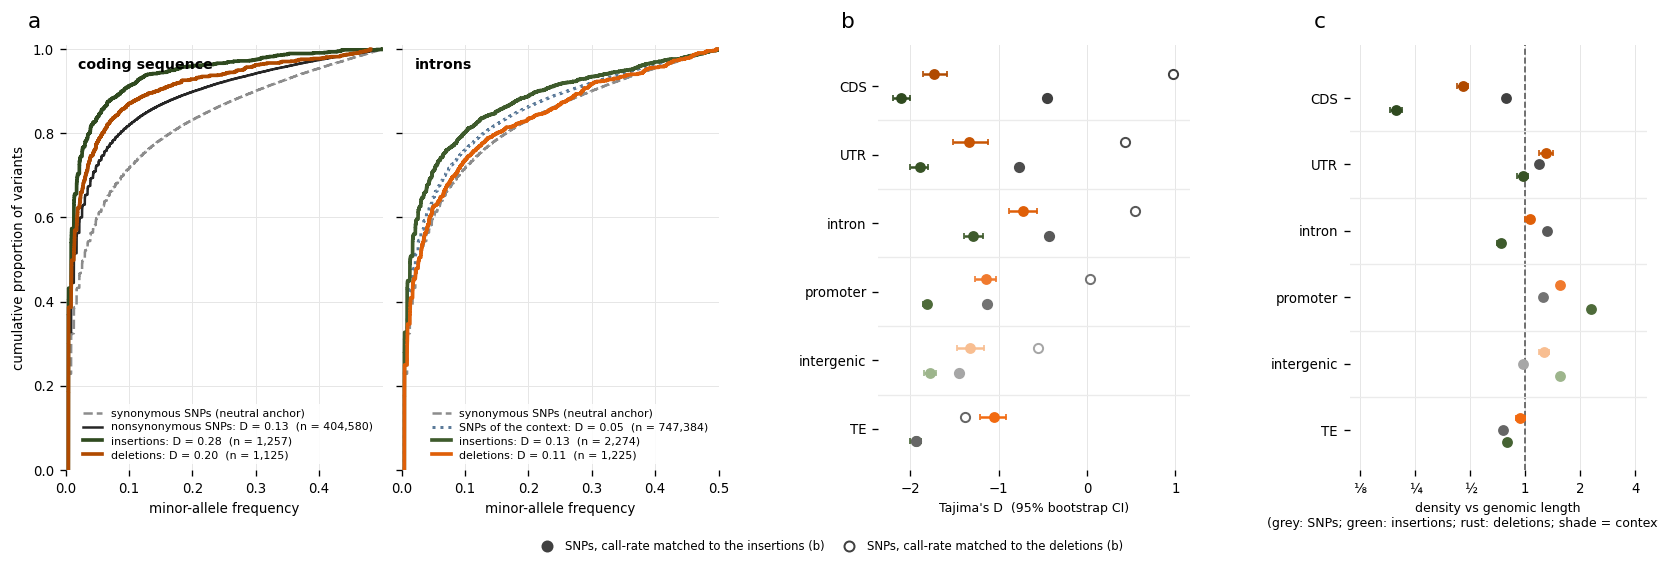

Figure 1a  cumulative spectra; KS vs synonymous SNPs:
context                              cls      n  maf_lt1  maf_lt5  maf_lt10  KS_D  KS_p
    CDS synonymous SNPs (neutral anchor) 394676    0.325    0.599     0.716 0.000   1.0
    CDS               nonsynonymous SNPs 404580    0.445    0.724     0.819 0.132   0.0
    CDS                       insertions   1257    0.574    0.837     0.912 0.277   0.0
    CDS                        deletions   1125    0.499    0.778     0.870 0.197   0.0
 intron synonymous SNPs (neutral anchor) 394676    0.325    0.599     0.716 0.000   1.0
 intron              SNPs of the context 747384    0.364    0.648     0.760 0.050   0.0
 intron                       insertions   2274    0.450    0.709     0.802 0.128   0.0
 intron                        deletions   1225    0.347    0.625     0.736 0.111   0.0

neutral reference check — synonymous / nonsynonymous vs the stricter 4-fold / 0-fold sites:
       cls      n  maf_lt5   TajD
   snp_syn 394676    0.599 

In [2]:

REF=maf("snp_syn")
def ecdf(a,v,**k):
    v=np.sort(v); return a.step(np.r_[v[0],v],np.r_[0,np.arange(1,v.size+1)/v.size],where="post",**k)
# local overrides of the shared _main_fig_common helpers, for this figure only: panel letters without
# bold (a touch larger to still stand out) and a save() helper that writes into notebooks/plots/ (this
# notebook's own directory), not results/sv_adaptive/plots/ as elsewhere in r1_sv_negative_selection
def panel(a,letter,x=-0.12,y=1.04): a.annotate(letter,xy=(x,y),xycoords="axes fraction",fontsize=13)
os.makedirs("plots",exist_ok=True)
def save(fig,name): fig.savefig(f"plots/{name}.png",dpi=200,bbox_inches="tight"); fig.savefig(f"plots/{name}.pdf",bbox_inches="tight")
# --- SV palette, matching sv_burden_final_models.ipynb: one hue per class (insertions green, deletions
# rust-orange, SNPs grey), darkest at CDS and lightest at intergenic. That notebook only needed
# CDS/promoter/intergenic; UTR/intron/TE are interpolated here at intermediate lightness, same hue.
# Overrides KC["ins"]/KC["del"] (shared orange/teal) LOCALLY, for this figure only.
CTXO=["CDS","UTR","intron","TE","promoter","intergenic"]
SVPAL={"ins_CDS":"#2F4A1F","ins_UTR":"#375325","ins_intron":"#3E5B2C","ins_TE":"#466333","ins_promoter":"#4E6B3A","ins_intergenic":"#9DB58C",
       "del_CDS":"#B04A00","del_UTR":"#C85503","del_intron":"#DF5F08","del_TE":"#F26A10","del_promoter":"#F07A2E","del_intergenic":"#F8BE91",
       "snp_CDS":"0.25","snp_UTR":"0.30","snp_intron":"0.35","snp_TE":"0.40","snp_promoter":"0.45","snp_intergenic":"0.65"}
SNPCTX="#5B7A99"                                     # slate blue: "SNPs of the context" line, kept distinct from the SVPAL greys
KC=dict(KC); KC["ins"]=SVPAL["ins_CDS"]; KC["del"]=SVPAL["del_CDS"]
fig=plt.figure(figsize=(17,4.6)); gs_=fig.add_gridspec(1,3,width_ratios=[2.2,1.05,1],wspace=0.38)
GSH=pd.read_csv(f"{G}/context_genome_share.csv").set_index("context").share.reindex(CTX).to_numpy()
S=np.load(f"{G}/sv_sfs_context_origin_event.npz"); m=S["snp_n"]>=2; ns=np.bincount(S["snp_ctx"][m],minlength=6); snp_sh=ns/ns.sum(); rs=snp_sh/GSH
TD={name:tajD_ci(name) for name in ["snp_syn","snp_nonsyn","snp_4fold","snp_0fold"]+[f"{k}_{x}" for k in ("snp","ins","del") for x in CTX]}
order=["TE","intergenic","promoter","intron","UTR","CDS"]; order_c=order                # same fixed order in (b) and (c): CDS at the bottom
OFF={"ins":-0.18,"del":0.18}; SF=[]; DENS={}
# (a) folded SFS as cumulative distributions: insertions and deletions together, coding sequence and introns apart.
# nonsynonymous SNPs only exist as a category in coding sequence, so that line is drawn there only; the intron
# panel gets the context-matched SNPs instead (the same local reference used throughout the supplement, Fig. S1).
# Legend labels name each line's ROLE, not just its identity, and every role has a visually distinct style:
# neutral anchor = light grey dashed; coding-only comparator = black solid; local reference = slate dotted;
# SV classes = the context-shaded SVPAL colour (darkest = CDS, here; lighter shades appear panel by panel below).
gsa=gs_[0,0].subgridspec(1,2,wspace=0.06); a1=fig.add_subplot(gsa[0,0]); a2=fig.add_subplot(gsa[0,1],sharey=a1)
for a,x,ttl in ((a1,"CDS","coding sequence"),(a2,"intron","introns")):
    style(a)
    LINES=[("snp_syn","synonymous SNPs (neutral anchor)","0.55","--",1.5)]
    LINES.append(("snp_nonsyn","nonsynonymous SNPs","0.15","-",1.5) if x=="CDS" else (f"snp_{x}","SNPs of the context",SNPCTX,":",1.8))
    LINES+=[(f"ins_{x}","insertions",SVPAL[f"ins_{x}"],"-",2.2),(f"del_{x}","deletions",SVPAL[f"del_{x}"],"-",2.2)]
    for name,lab,col,ls,lw in LINES:
        v=maf(name); ks=stats.ks_2samp(v,REF)
        lab_full=lab if name=="snp_syn" else f"{lab}: D = {ks.statistic:.2f}  (n = {v.size:,})"
        ecdf(a,v,color=col,ls=ls,lw=lw,label=lab_full)
        SF.append(dict(context=x,cls=lab,n=v.size,maf_lt1=(v<0.01).mean(),maf_lt5=(v<0.05).mean(),maf_lt10=(v<0.10).mean(),KS_D=ks.statistic,KS_p=ks.pvalue))
    a.set_xlim(0,0.5); a.set_ylim(0,1.01); a.set_xlabel("minor-allele frequency"); a.set_xticks([0,0.1,0.2,0.3,0.4]+([0.5] if x=="intron" else []))
    a.annotate(ttl,xy=(0.04,0.97),xycoords="axes fraction",ha="left",va="top",fontsize=8.5,fontweight="bold")
    a.legend(loc="lower right",fontsize=6.6,frameon=True,framealpha=0.85,edgecolor="none",handlelength=1.7,labelspacing=0.35,borderaxespad=0.5)
a1.set_ylabel("cumulative proportion of variants"); a2.tick_params(labelleft=False); panel(a1,"a")
# (b) Tajima's D per context: insertions and deletions against SNPs of the same context drawn to the same call-rate
# distribution; point colour = the same context shade as (a)/(S1) (context is also given by row, so colour here is
# a redundant cross-check, not the primary read)
a=fig.add_subplot(gs_[0,1]); style(a,axis="x"); panel(a,"b"); DD_={}; TM={}
for i,x in enumerate(order):
    for k in ("ins","del"):
        y=i+OFF[k]; v_=TD[f"{k}_{x}"]; m_=tajD_matched(f"snp_{x}",f"{k}_{x}"); TM[(k,x)]=m_; DD_[(k,x)]=(v_[0]-m_[0],v_[1]-m_[0],v_[2]-m_[0])
        a.errorbar(m_[0],y,xerr=[[m_[0]-m_[1]],[m_[2]-m_[0]]],fmt="o",color=SVPAL[f"snp_{x}"],mfc="white" if k=="del" else SVPAL[f"snp_{x}"],mew=1.2,ms=5.5,capsize=2,zorder=4)
        a.errorbar(v_[0],y,xerr=[[v_[0]-v_[1]],[v_[2]-v_[0]]],fmt="o",color=SVPAL[f"{k}_{x}"],ms=5.5,capsize=2,zorder=3)
    if i<len(order)-1: a.axhline(i+0.5,color="0.92",lw=0.8)
a.set_yticks(range(len(order))); a.set_yticklabels(order); a.set_ylim(-0.6,len(order)-0.4)
a.set_xlabel("Tajima's D  (95% bootstrap CI)",fontsize=7.5)
gap=TD["snp_nonsyn"][0]-TD["snp_syn"][0]
# (c) where they are found: share in context / share of genomic length; same context-shaded colours as (a)-(b)
a=fig.add_subplot(gs_[0,2]); style(a,axis="x"); panel(a,"c"); a.axvline(1,color="0.35",lw=1,ls="--")
for k in ("ins","del"):
    nk=E[E.kind==k].context.value_counts().reindex(CTX).to_numpy(); sh=nk/nk.sum(); rk=sh/GSH; DENS[KL[k]]=rk
    for j,x in enumerate(order_c):
        i=CTX.index(x); y=j+OFF[k]
        a.errorbar(rk[i],y,xerr=1.96*np.sqrt(sh[i]*(1-sh[i])/nk.sum())/GSH[i],fmt="o",color=SVPAL[f"{k}_{x}"],ms=5.5,capsize=2,zorder=3)
for j,x in enumerate(order_c):
    i=CTX.index(x); a.errorbar(rs[i],j,xerr=1.96*np.sqrt(snp_sh[i]*(1-snp_sh[i])/ns.sum())/GSH[i],fmt="o",color=SVPAL[f"snp_{x}"],ms=5.5,capsize=2,zorder=4)
    if j<5: a.axhline(j+0.5,color="0.92",lw=0.8)
a.set_xscale("log",base=2); a.set_xticks([0.125,0.25,0.5,1,2,4]); a.set_xticklabels(["⅛","¼","½","1","2","4"]); a.set_xlim(0.11,4.6)
a.set_yticks(range(6)); a.set_yticklabels(order_c); a.set_ylim(-0.6,5.8); a.set_xlabel("density vs genomic length\n(grey: SNPs; green: insertions; rust: deletions; shade = context, as in a-b)",fontsize=7.5)
# panel a is self-labelled (its own in-panel legend, above); this legend is only for the two marker
# roles unique to panel b (its dot colours are already keyed to panel a via the shared SVPAL context shades)
LEG=[("SNPs, call-rate matched to the insertions (b)",SVPAL["snp_CDS"],SVPAL["snp_CDS"]),
     ("SNPs, call-rate matched to the deletions (b)",SVPAL["snp_CDS"],"white")]
h_=[a1.plot([],[],"o",color=c,mfc=fc,mew=1.2,ms=6)[0] for _,c,fc in LEG]; l_=[lab for lab,_,_ in LEG]
fig.legend(h_,l_,frameon=False,fontsize=7,loc="lower center",bbox_to_anchor=(0.5,-0.06),ncol=2,columnspacing=1.3,handlelength=1.5)
save(fig,"main_fig1"); plt.show()
print("Figure 1a  cumulative spectra; KS vs synonymous SNPs:"); print(pd.DataFrame(SF).drop_duplicates(["context","cls"]).round(3).to_string(index=False))
print("\nneutral reference check — synonymous / nonsynonymous vs the stricter 4-fold / 0-fold sites:")
print(pd.DataFrame([dict(cls=n_,n=maf(n_).size,maf_lt5=(maf(n_)<0.05).mean(),TajD=TD[n_][0]) for n_ in ("snp_syn","snp_4fold","snp_nonsyn","snp_0fold")]).round(3).to_string(index=False))
print("\nFigure 1b  Tajima's D [95% CI]:"); print(pd.DataFrame({k_:dict(D=v[0],lo=v[1],hi=v[2]) for k_,v in TD.items()}).T.round(2).to_string())
print(f"\nFigure 1b  Tajima's D: SV class, SNPs of the context (all), SNPs call-rate matched to the class, and the class minus the matched SNPs [95% CI]; for scale, nonsynonymous - synonymous SNPs = {gap:+.2f}")
print(pd.DataFrame({f"{KL[k]} {x}":dict(D_class=TD[f"{k}_{x}"][0],D_snps_all=TD[f"snp_{x}"][0],D_snps_matched=TM[(k,x)][0],dD_matched=v[0],lo=v[1],hi=v[2]) for (k,x),v in DD_.items()}).T.round(2).to_string())
print("\nFigure 1c  share / genomic share:"); print(pd.DataFrame(dict(genome=GSH,SNPs=rs,**DENS),index=CTX).round(2).to_string())
# reading frame (not drawn): share of events whose length is a multiple of 3 (1/3 expected outside coding sequence)
I=E[E.kind=="ins"]; C=I[I.context=="CDS"]; rows=[]
for lab,d in (("CDS insertions, gene duplicate",C[C.seq_class=="gene_dup"]),("CDS insertions, TE-derived",C[C.seq_class=="te_derived"]),("all CDS insertions",C),
              ("CDS deletions",E[(E.kind=="del")&(E.context=="CDS")]),("insertions, other contexts",I[I.context!="CDS"])):
    x_=int((d.size_bp%3==0).sum()); n=len(d); ci=stats.binomtest(x_,n,1/3).proportion_ci(); rows.append(dict(group=lab,n=n,in_frame=x_/n,lo=ci.low,hi=ci.high))
print("\nreading frame (not drawn):"); print(pd.DataFrame(rows).round(3).to_string(index=False))
print("\nrobustness — with singletons (1) and without (minor-allele count >= 2): share MAF < 5%, KS D vs synonymous SNPs")
print(CKS.pivot(index="cls",columns="min_minor_count",values=["maf_lt5","KS_D"]).reindex(["snp_syn","snp_nonsyn","ins_CDS","ins_UTR","ins_intron","ins_TE","ins_promoter","ins_intergenic","del_CDS"]).round(3).to_string())


## Figure 1b, replotted — the call-rate-matched gradient

Panel 1b draws the class and its call-rate-matched SNP reference as two separate points; the quantity the
purifying-selection argument actually rests on is the **gap between them**, which is hard to read off two
overlapping point clouds. Here that difference is plotted directly, from the same numbers (`DD_`, printed
under Figure 1).

**What it is.** Tajima's *D* of the SV class minus Tajima's *D* of SNPs drawn to the *same distribution of
called founders* — i.e. the part of the class's rare-variant shift that is **not** explained by how
completely the pangenome calls it. Below 0 = shifted towards rare beyond its matched SNPs.

**Why it carries the argument.** The coding-sequence spectrum in Figure 1a is a single comparison, and it
has an available technical explanation: complete calls select simple pangenome bubbles, which are
themselves enriched for rare variants. That explanation predicts a shift everywhere the calling is hard.
What the data show instead is a **gradient that tracks functional density and vanishes in reference TEs** —
and a calling artifact has no way to know where the exons are. Two reference lines are drawn: 0
(indistinguishable from matched SNPs) and the nonsynonymous − synonymous gap, the canonical
selected-vs-neutral shift measured in this same panel, as the yardstick for how large a shift is large.

*Caveat.* The interval is the class's own bootstrap CI recentred on the matched-SNP point estimate, so it
carries the class's uncertainty but not the matching step's; read it as a precision on the class, not a
formal test of the difference. The ordering is robust to that — the CDS-to-TE span is several times the
width of any individual interval. Note also that insertions and deletions **swap rank** between this
statistic and Figure 1a's KS *D*, because their matched-SNP baselines differ (CDS: +0.97 for deletions,
−0.45 for insertions); the context gradient holds in both, the insertion-vs-deletion ranking does not, so
quote the gradient and not the ranking.

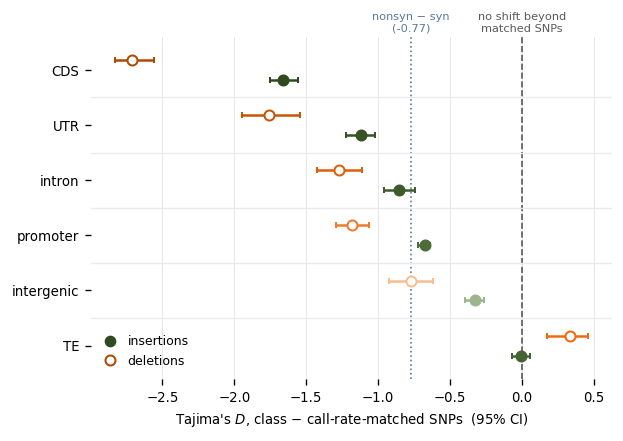

Call-rate-matched Tajima's D gap (class − matched SNPs), CDS → TE; nonsynonymous − synonymous SNPs = -0.77
   context        cls  dD_matched    lo    hi
       CDS insertions       -1.66 -1.75 -1.56
       CDS  deletions       -2.71 -2.83 -2.56
       UTR insertions       -1.12 -1.23 -1.02
       UTR  deletions       -1.76 -1.95 -1.55
    intron insertions       -0.86 -0.96 -0.75
    intron  deletions       -1.27 -1.42 -1.11
  promoter insertions       -0.68 -0.72 -0.64
  promoter  deletions       -1.18 -1.30 -1.06
intergenic insertions       -0.33 -0.40 -0.26
intergenic  deletions       -0.77 -0.93 -0.62
        TE insertions       -0.00 -0.07  0.06
        TE  deletions        0.33  0.18  0.46


In [3]:

# The Figure 1b gap, drawn. DD_[(class, context)] = (dD, lo, hi) was computed for Figure 1b and only
# printed; nothing plotted it. Same palette, same context order as 1b, so a row matches across figures.
fig,a=plt.subplots(figsize=(5.6,3.7)); style(a,axis="x")
a.axvline(0,color="0.35",lw=1,ls="--"); a.axvline(gap,color=SNPCTX,lw=1,ls=":")
for i,x in enumerate(order):
    for k in ("ins","del"):
        d,lo,hi=DD_[(k,x)]; y=i+OFF[k]
        a.errorbar(d,y,xerr=[[d-lo],[hi-d]],fmt="o",color=SVPAL[f"{k}_{x}"],
                   mfc="white" if k=="del" else SVPAL[f"{k}_{x}"],mew=1.2,ms=6,capsize=2,zorder=3)
    if i<len(order)-1: a.axhline(i+0.5,color="0.92",lw=0.8)
a.set_yticks(range(len(order))); a.set_yticklabels(order); a.set_ylim(-0.6,len(order)-0.4)
a.set_xlabel("Tajima's $D$, class − call-rate-matched SNPs  (95% CI)",fontsize=8)
a.annotate("no shift beyond\nmatched SNPs",xy=(0,1.01),xycoords=("data","axes fraction"),
           ha="center",va="bottom",fontsize=6.8,color="0.35")
a.annotate(f"nonsyn − syn\n({gap:+.2f})",xy=(gap,1.01),xycoords=("data","axes fraction"),
           ha="center",va="bottom",fontsize=6.8,color=SNPCTX)
h_=[a.plot([],[],"o",color=SVPAL["ins_CDS"],ms=6)[0],
    a.plot([],[],"o",color=SVPAL["del_CDS"],mfc="white",mew=1.2,ms=6)[0]]
a.legend(h_,["insertions","deletions"],frameon=False,fontsize=7.5,loc="lower left",handlelength=1.2)
save(fig,"main_fig1_matched_gradient"); plt.show()
print(f"Call-rate-matched Tajima's D gap (class − matched SNPs), CDS → TE; nonsynonymous − synonymous SNPs = {gap:+.2f}")
print(pd.DataFrame([dict(context=x,cls=KL[k],dD_matched=DD_[(k,x)][0],lo=DD_[(k,x)][1],hi=DD_[(k,x)][2])
                    for x in order[::-1] for k in ("ins","del")]).round(2).to_string(index=False))


## Supplementary Figure S1 — Folded spectra in every genomic context

Figure 1a for all six contexts. One panel per context (first match wins: CDS > UTR > intron >
reference TE > promoter > intergenic): cumulative distribution of minor-allele frequency for insertions
and deletions of that context, against synonymous SNPs (neutral reference, light grey dashed), the one
anchor reused in every panel. Insertions and deletions use the SV palette of `sv_burden_final_models.ipynb`
(green / rust-orange respectively), one shade per context, darkest at CDS and lightest at intergenic —
so the same context is the same shade in every figure that uses this palette, and a panel's own two SV
lines are always the darkest-shaded lines on that panel. **Nonsynonymous SNPs (black, solid) are drawn
only in the coding-sequence panel** — "nonsynonymous" is a codon property and does not exist for a UTR,
intron, TE, promoter or intergenic site, so the other five panels do not carry that line. In its place
they show SNPs of the context itself (slate blue, dotted): does an SV class sit further from neutral
than the context's own SNPs do? This is the locally meaningful comparison, and it is not automatically
the same thing as distance from synonymous SNPs — SNPs in reference TEs, promoters and intergenic
sequence are themselves shifted towards rare variants relative to synonymous SNPs (most sharply in TEs,
more than the nonsynonymous/synonymous gap in the CDS panel), so in those panels the distance of an SV
class from the synonymous line is not a selective shift by itself (Figure 1b makes the same comparison
with Tajima's *D*, call-rate matched). *Caveat:* unlike panel 1b, the context-SNP line here is not
call-rate matched to the SV class, so in low-callability contexts (TE) part of its own rare-shift may be
a genotyping artifact rather than constraint. Two-sample Kolmogorov–Smirnov *D* against synonymous SNPs
in each panel, and against the SNPs of the context in the table printed below. Same variants and filters
as Figure 1a (called in ≥ 90% of the 231 founders, singletons included).

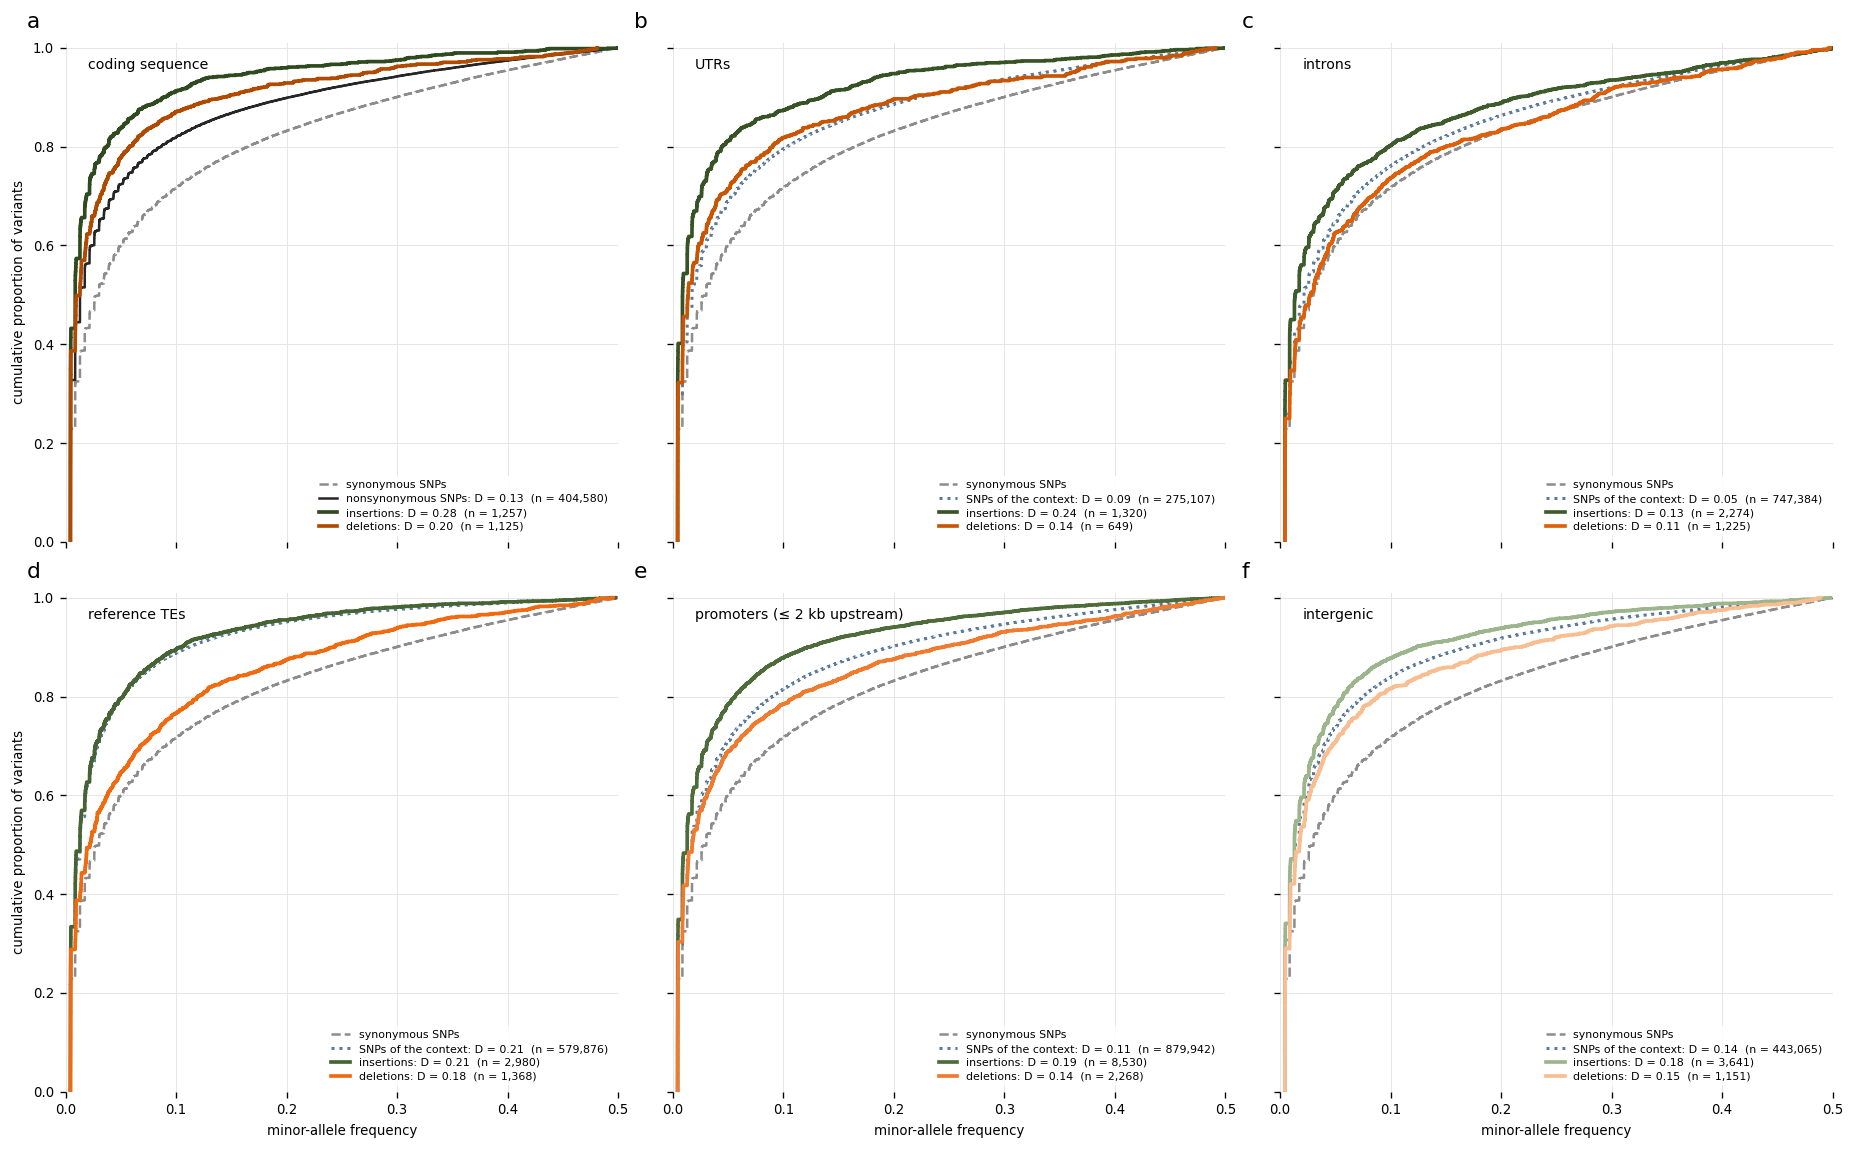

Supplementary Figure S1  per context: share of variants below MAF 1 / 5 / 10%; KS D against synonymous SNPs and against the SNPs of the same context
(above_context_SNPs: the class has a larger share below MAF 5% than the context's SNPs, i.e. sits above the dotted line)
   context                 cls      n  maf_lt1  maf_lt5  maf_lt10  KS_D_vs_syn  KS_D_vs_context_SNPs  above_context_SNPs
       CDS          insertions   1257    0.574    0.837     0.912        0.277                 0.210                True
       CDS           deletions   1125    0.499    0.778     0.870        0.197                 0.151                True
       UTR SNPs of the context 275107    0.405    0.689     0.794        0.094                 0.000               False
       UTR          insertions   1320    0.543    0.811     0.873        0.237                 0.148                True
       UTR           deletions    649    0.456    0.715     0.818        0.138                 0.153                True
    

In [4]:

# nonsynonymous SNPs are a CDS-only category (needs a codon), so that line is drawn in the CDS panel
# only; every other panel gets "SNPs of the context" (dotted) in its place -- the local reference.
# Colour: SVPAL context shade for insertions/deletions (defined in the cell above), so a context is the
# same shade everywhere in this figure and in sv_burden_final_models.ipynb; the reference-SNP lines keep
# their fixed, mutually distinct styles (light grey dashed / black solid / slate dotted) in every panel.
# Each panel carries its OWN legend (line style/colour + KS D + n), so it is readable on its own without
# cross-referencing another panel or a caption; curves are monotonic 0->1 and (being folded MAF, mostly
# rare variants) are already near 1 by MAF ~0.3, so the lower-right corner is reliably empty for the legend.
PAN=[("CDS","coding sequence"),("UTR","UTRs"),("intron","introns"),("TE","reference TEs"),("promoter","promoters (≤ 2 kb upstream)"),("intergenic","intergenic")]
fig,ax=plt.subplots(2,3,figsize=(15.5,9.6),sharex=True,sharey=True); S1=[]
for a,(x,ttl),letter in zip(ax.ravel(),PAN,"abcdef"):
    style(a); loc=maf(f"snp_{x}")
    LINES=[("snp_syn","synonymous SNPs","0.55","--",1.5)]
    LINES.append(("snp_nonsyn","nonsynonymous SNPs","0.15","-",1.5) if x=="CDS" else (f"snp_{x}","SNPs of the context",SNPCTX,":",1.8))
    LINES+=[(f"ins_{x}","insertions",SVPAL[f"ins_{x}"],"-",2.2),(f"del_{x}","deletions",SVPAL[f"del_{x}"],"-",2.2)]
    for name,lab,col,ls,lw in LINES:
        v=maf(name); ks=stats.ks_2samp(v,REF); ksl=stats.ks_2samp(v,loc)
        lab_full=lab if name=="snp_syn" else f"{lab}: D = {ks.statistic:.2f}  (n = {v.size:,})"
        ecdf(a,v,color=col,ls=ls,lw=lw,label=lab_full)
        S1.append(dict(context=x,cls=lab,n=v.size,maf_lt1=(v<0.01).mean(),maf_lt5=(v<0.05).mean(),maf_lt10=(v<0.10).mean(),
                       KS_D_vs_syn=ks.statistic,KS_D_vs_context_SNPs=ksl.statistic,above_context_SNPs=bool(np.mean(v<0.05)>np.mean(loc<0.05))))
    a.set_xlim(0,0.5); a.set_ylim(0,1.01); a.set_xticks([0,0.1,0.2,0.3,0.4,0.5])
    a.annotate(ttl,xy=(0.04,0.97),xycoords="axes fraction",ha="left",va="top",fontsize=8.5)
    a.legend(loc="lower right",fontsize=6.6,frameon=True,framealpha=0.85,edgecolor="none",handlelength=1.7,labelspacing=0.35,borderaxespad=0.5)
    panel(a,letter,x=-0.07,y=1.03)
for a in ax[1]: a.set_xlabel("minor-allele frequency")
for a in ax[:,0]: a.set_ylabel("cumulative proportion of variants")
fig.tight_layout(); save(fig,"supp_fig1_sfs_by_context"); plt.show()
T=pd.DataFrame(S1); T=T[~T.cls.isin(["synonymous SNPs","nonsynonymous SNPs"])]
print("Supplementary Figure S1  per context: share of variants below MAF 1 / 5 / 10%; KS D against synonymous SNPs and against the SNPs of the same context")
print("(above_context_SNPs: the class has a larger share below MAF 5% than the context's SNPs, i.e. sits above the dotted line)")
print(T.round(3).to_string(index=False))


## Supplementary Figure S2 — the same spectra, against a call-rate-matched reference

Figure S1 compares every class to one fixed anchor: genome-wide synonymous SNPs. That anchor is neither
in the class's genomic context nor called in the same number of founders, and callability moves these
spectra a lot — reweighting coding SNPs by call rate alone shifts Tajima's *D* by 1.42, nearly twice the
whole nonsynonymous-versus-synonymous gap of 0.77. So a gap against the synonymous line is not, by
itself, a selective shift.

Here each class is drawn against **its own reference**: SNPs **of the same context**, resampled to that
class's exact distribution of called founders — the *identical* SNP draw that Figure 1b's matched
Tajima's *D* uses (`maf_matched` and `tajD_matched` now share one sampler, `_match_pick`, so the two
figures cannot drift apart). Insertions and deletions therefore have *different* reference curves, drawn
in the class's own hue, dashed; the class itself is solid. The Kolmogorov–Smirnov *D* in each legend is
the class against **that** reference, so it is the spectrum-level counterpart of the matched Tajima's *D*
gap, and it is not comparable to S1's *D* (different reference).

The matching is exact here, not approximate: across all twelve class × context combinations, **0% of
variants sit at a call-rate value with no available SNP, and 0% of strata are capped by availability**
(reported by `_match_pick`). Read each panel as: does the solid line sit above its own dashed line?

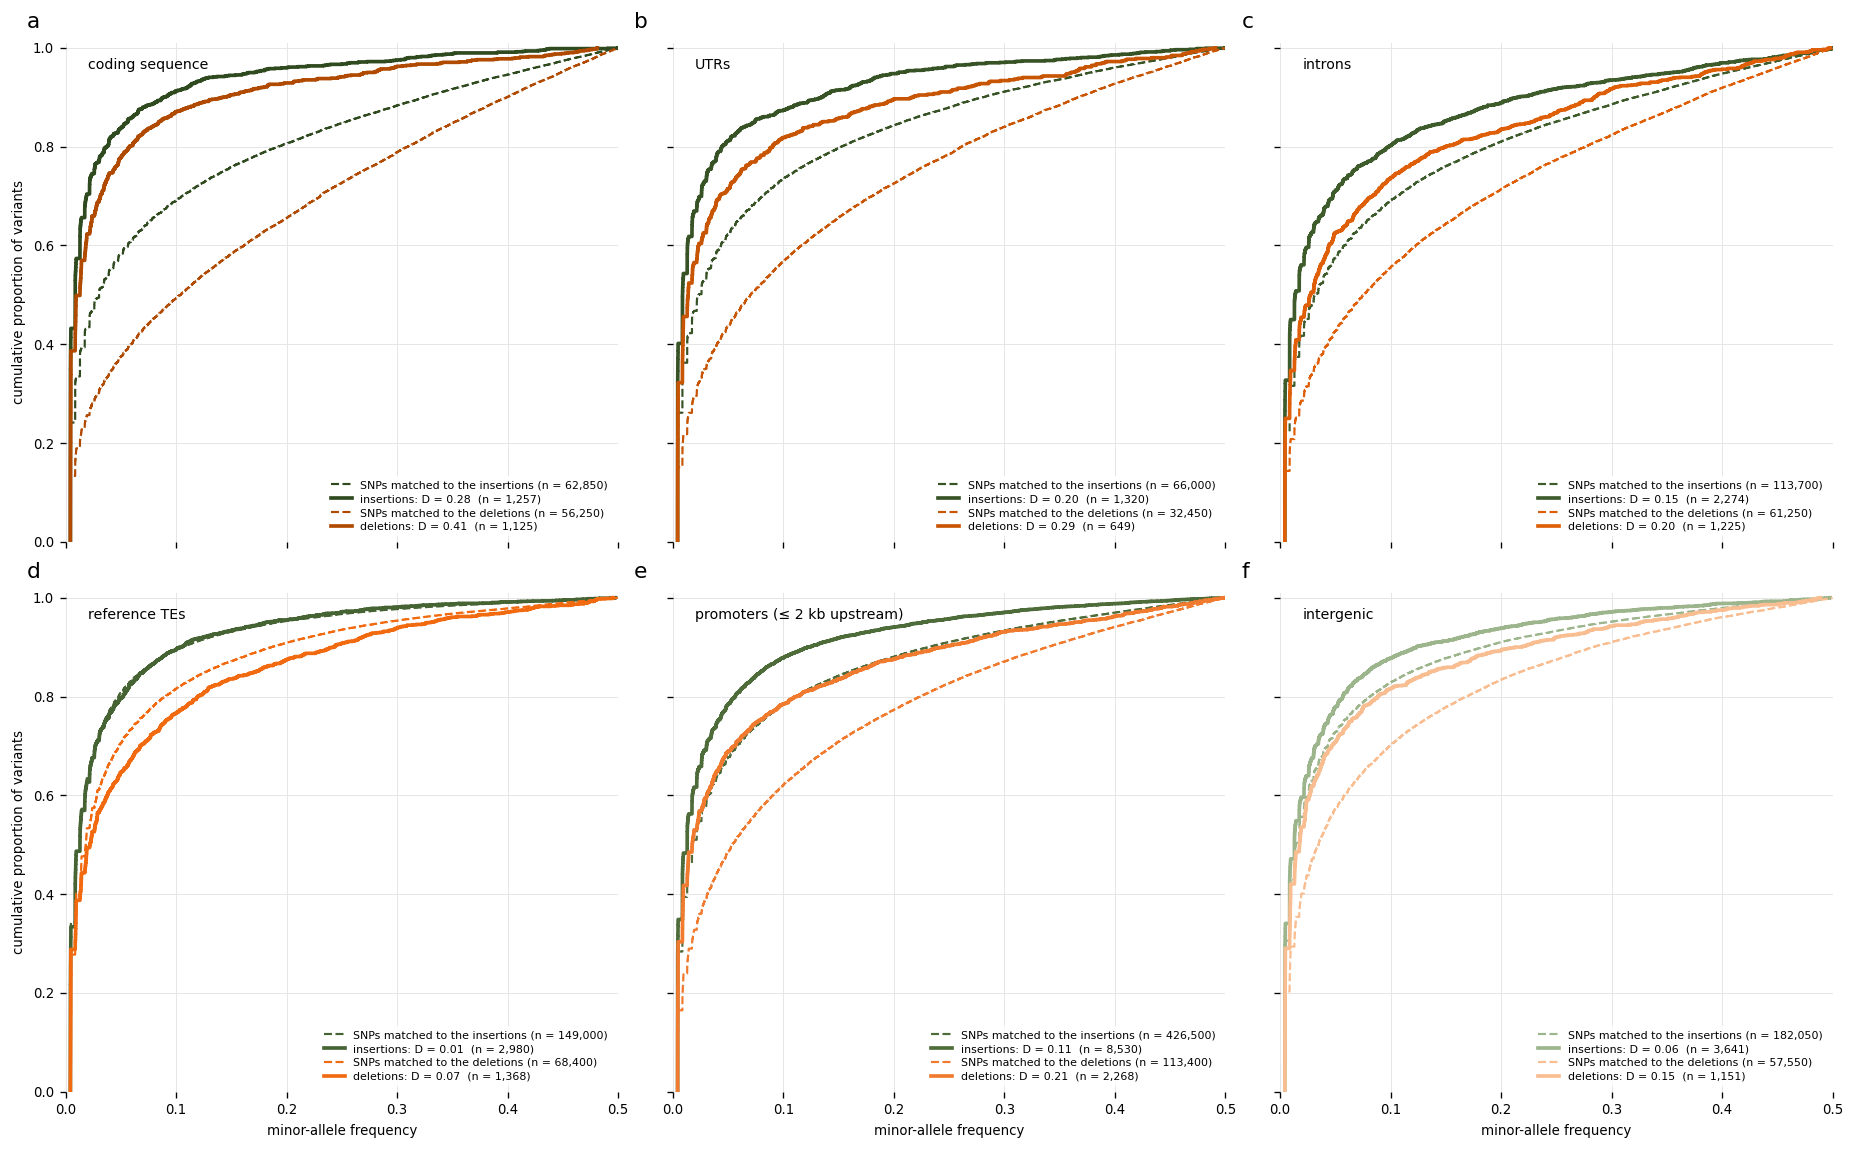

Supplementary Figure S2  KS D against the class's OWN call-rate-matched, same-context SNPs,
with S1's D against synonymous SNPs and Figure 1b's matched Tajima's D gap for comparison:
   context        cls    n  KS_D_vs_matched  KS_D_vs_syn  dD_tajima  above_matched
       CDS insertions 1257            0.278        0.277     -1.658           True
       CDS  deletions 1125            0.406        0.197     -2.711           True
       UTR insertions 1320            0.203        0.237     -1.122           True
       UTR  deletions  649            0.294        0.138     -1.761           True
    intron insertions 2274            0.148        0.128     -0.856           True
    intron  deletions 1225            0.199        0.111     -1.272           True
        TE insertions 2980            0.013        0.215     -0.003          False
        TE  deletions 1368            0.065        0.185      0.334          False
  promoter insertions 8530            0.114        0.193     -0.677   

In [5]:

# Same six contexts as S1, but every class against SNPs of its own context resampled to its own call-rate
# distribution -- the same draw tajD_matched uses. Insertions and deletions get SEPARATE references (their
# call-rate distributions differ a lot: CDS median k 230 vs 220), so each panel carries two dashed lines.
fig,ax=plt.subplots(2,3,figsize=(15.5,9.6),sharex=True,sharey=True); S2=[]; REP=[]
for a,(x,ttl),letter in zip(ax.ravel(),PAN,"abcdef"):
    style(a)
    for k in ("ins","del"):
        v=maf(f"{k}_{x}"); ref_k,rep=maf_matched(f"snp_{x}",f"{k}_{x}")
        ks=stats.ks_2samp(v,ref_k); ks_syn=stats.ks_2samp(v,REF)
        ecdf(a,ref_k,color=SVPAL[f"{k}_{x}"],ls="--",lw=1.3,
             label=f"SNPs matched to the {KL[k]} (n = {ref_k.size:,})")
        ecdf(a,v,color=SVPAL[f"{k}_{x}"],ls="-",lw=2.2,
             label=f"{KL[k]}: D = {ks.statistic:.2f}  (n = {v.size:,})")
        S2.append(dict(context=x,cls=KL[k],n=v.size,KS_D_vs_matched=ks.statistic,KS_D_vs_syn=ks_syn.statistic,
                       dD_tajima=DD_[(k,x)][0],above_matched=bool(np.mean(v<0.05)>np.mean(ref_k<0.05))))
        REP.append(dict(context=x,cls=KL[k],**rep))
    a.set_xlim(0,0.5); a.set_ylim(0,1.01); a.set_xticks([0,0.1,0.2,0.3,0.4,0.5])
    a.annotate(ttl,xy=(0.04,0.97),xycoords="axes fraction",ha="left",va="top",fontsize=8.5)
    a.legend(loc="lower right",fontsize=6.6,frameon=True,framealpha=0.85,edgecolor="none",
             handlelength=1.9,labelspacing=0.35,borderaxespad=0.5)
    panel(a,letter,x=-0.07,y=1.03)
for a in ax[1]: a.set_xlabel("minor-allele frequency")
for a in ax[:,0]: a.set_ylabel("cumulative proportion of variants")
fig.tight_layout(); save(fig,"supp_fig2_sfs_callrate_matched"); plt.show()
T2=pd.DataFrame(S2)
print("Supplementary Figure S2  KS D against the class's OWN call-rate-matched, same-context SNPs,")
print("with S1's D against synonymous SNPs and Figure 1b's matched Tajima's D gap for comparison:")
print(T2.round(3).to_string(index=False))
R=pd.DataFrame(REP)
print(f"\nmatch quality: max unmatched {R.frac_unmatched.max():.2%}, max capped {R.frac_capped.max():.2%} "
      f"(over {len(R)} class x context draws)")


## Models and statistics, as run

- **Spectra (Fig. 1a; 3a).** Per variant, carriers *c* among *k* called founders (k ≥ 208 of 231,
  1 ≤ c ≤ k − 1; singletons included); folded MAF = min(c/k, 1 − c/k). Two-sample Kolmogorov–Smirnov on
  MAF against synonymous SNPs (effect size *D* reported; p-values are driven by *n*).
  Tajima's *D* = (π − S/a₁) / √(e₁S + e₂S(S−1)) with the Tajima (1989) constants for n = median called
  founders of the class, π = Σ<sub>v</sub> 2c<sub>v</sub>(k<sub>v</sub> − c<sub>v</sub>)/(k<sub>v</sub>(k<sub>v</sub> − 1)),
  S = number of variants; CI from bootstrap resampling of variants (300 draws; 40 for the SNP classes,
  whose CI is negligible). No down-projection: variants are called in a median of 216–231 of 231
  founders, and projecting to a common sample of 200 changes *D* by < 0.03 in every class. Degeneracy: standard code, reference codon, `.1` gene models; sites with conflicting
  models dropped.
- **Density (Fig. 1c).** Share of a class in a context ÷ exact base-pair share of the context
  (Chr1–5, same first-match rule); 95% CI from the binomial SE of the share.
- **Frame (not drawn; printed under Fig. 1).** Binomial test of the in-frame share against 1/3.
- **Robustness (`_sv_main_figures_checks.py`).** Burden model with founder origin bio1 (and bio1²) as
  extra covariates: β₁ unchanged (−0.22); the burden–fitness relation holds within origin tertiles
  (cold ρ = −0.51, warm ρ = −0.27). Spectra without singletons (minor-allele count ≥ 2): same ordering
  (values printed under Figure 1).